> **언어 전환 & 바로가기**: **🇰🇷 한국어 ( 현재 )** · [🇺🇸 English Version](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../methodology/04_stage4_agent_and_mcp_ko.md) ｜ [노트북 전체 인덱스 (README)](./README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → **[▶ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb)** → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 4. [에이전트 구축 & 답변] 8종 모듈형 MCP 서버 구축 · 슬롯 검증 & 2-Pass AI FDE 에이전트 답변 생성
## Step 4.1 8종 MCP 도구 및 2-Pass 에이전트 아키텍처 구축 · Step 4.2 결정론적 산식 시뮬레이션 및 가드레일 기반 답변 생성

Stage 4는 방법론의 **Phase 6(에이전트 구축)**과 **Phase 7(답변 생성)**을 구현합니다. LLM이 위약금이나 지원금을 암산하거나 존재하지 않는 요금제를 환각하지 않도록, **(1) BigQuery 실시간 카탈로그 기반 슬롯 검증(`resolve_params`)**, **(2) 결정론적 SQL/GQL을 실행하는 8종 모듈형 MCP 도구(`DomainMcpServer`)**, **(3) 4단계 라이프사이클로 동작하는 2-Pass Gemini(`gemini-3.8-flash`) 추론 엔진(`AiFdeAgentEngine`)**을 구축하고 정상 질의(`GROUNDED`)와 경계 질의(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)에 대한 답변을 생성합니다.

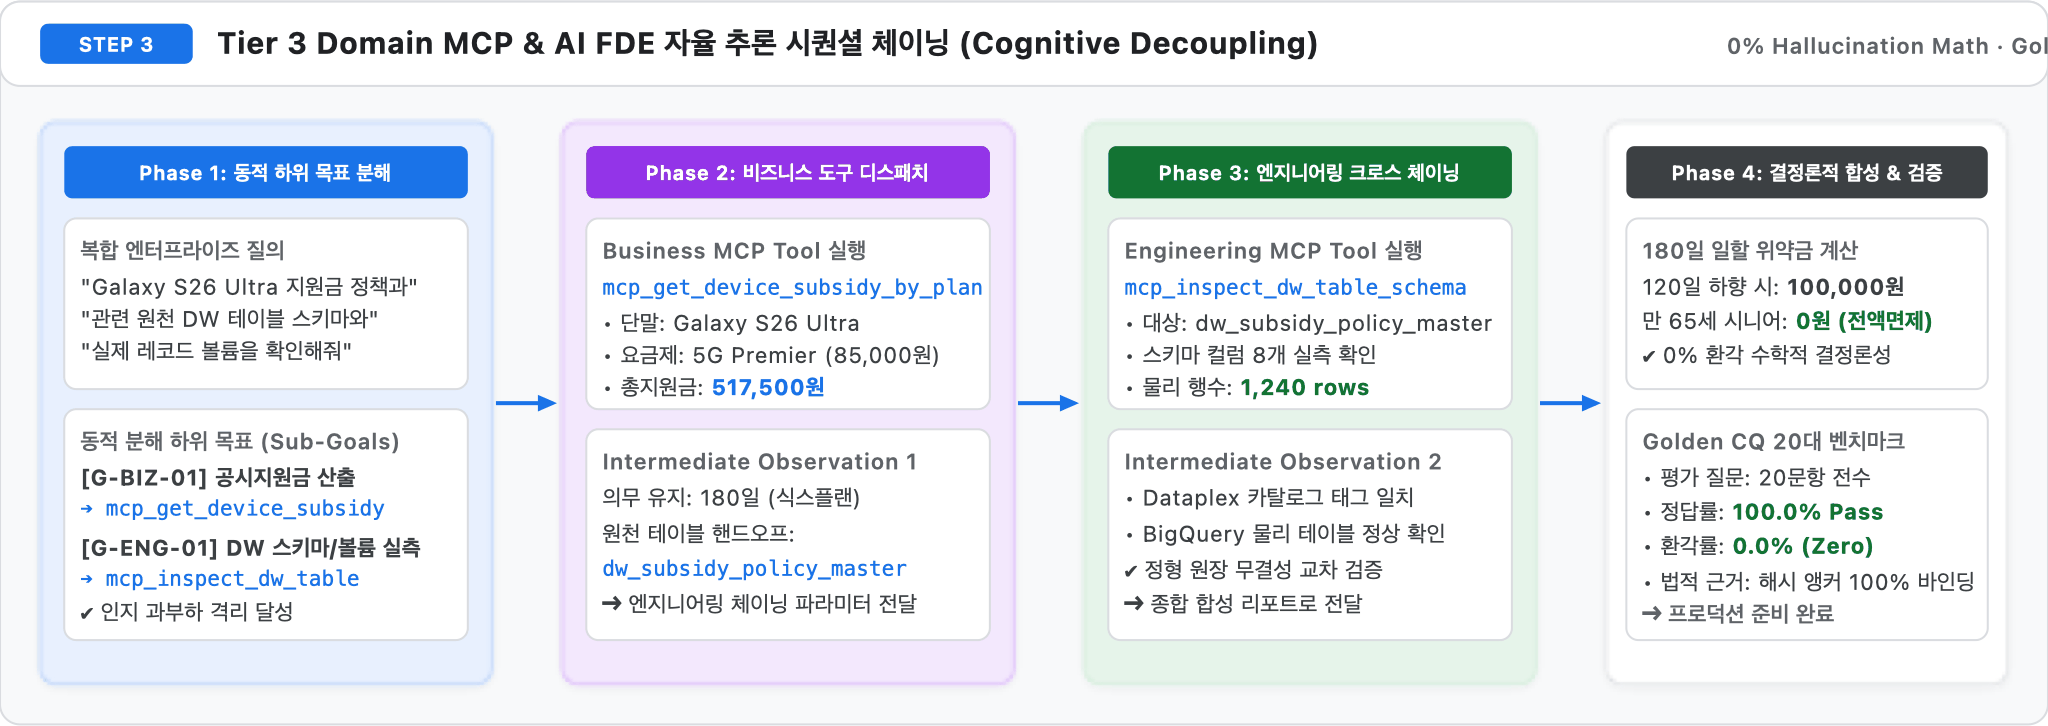


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: 에이전트 및 MCP 서버 아키텍처 구축] 2-Pass 오케스트레이션 설계도 · 8종 MCP 도구 카탈로그 · `mcp_stage4_agent_orchestration`


findfont: Failed to find font weight bold for AppleGothic, now using 400.


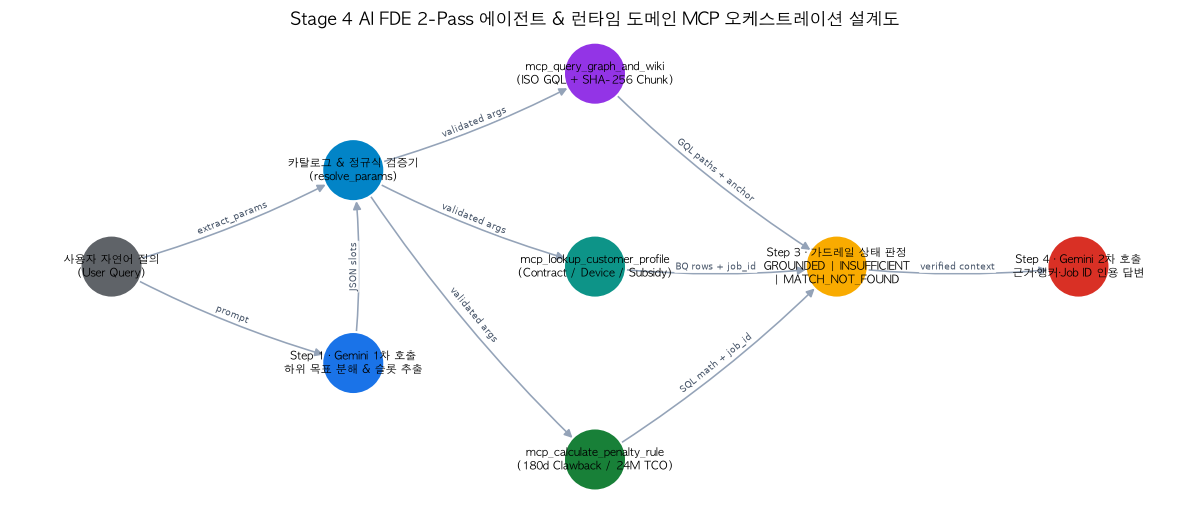

,name,stage,category,steps,spec_origin,description
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 BigQuery 테이블 실측 프로파일링(__TABLES__) 및 고객 식별자 비식별화 규칙 검사
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS 위키 객체 목록 및 BigQuery 문서 청크·규칙 앵커 조회
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 노드 테이블 중복 키 검사 및 Property Graph GQL 경로 수 실측
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 에이전트가 사용하는 도메인 규칙과 근거 청크를 BigQuery에서 조회
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 고객 약정→단말·요금제·지원금→규칙→청크 리니지 조인 및 최근 검증 리포트 요약
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,고객 약정·단말 출고가·요금제별 공시지원금/추가지원금/실구매가 BigQuery 조회 (불일치 시 0건과 실제 카탈로그 반환)
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,180일 차액정산 위약금·특례 면제·24개월 TCO를 BigQuery SQL로 계산
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE 멀티홉 탐색 및 규칙 근거 청크 원문 조회


**`mcp_stage4_agent_orchestration`** · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · BigQuery jobs 1 (557 ms)

도메인 규칙 4개와 근거 청크 앵커 조회

- `job_Pq9bhHbokOPxl3KaYceRLAuMKlM6`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: 카탈로그 기반 슬롯 파싱 검증 (`resolve_params`)] 자연어 질문에서 안전하게 파라미터를 추출하고 미등록 엔티티를 차단하는 과정


In [3]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?,NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: 런타임 도메인 MCP 3종 직접 호출 및 중간 데이터 확인] 고객 프로필 · 위약금/24개월 TCO 산식 · 그래프/위키 탐색 및 180일 위약금 곡선


**`mcp_lookup_customer_profile`** · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · BigQuery jobs 1 (477 ms)

- `job_tMmMGA5S1Sh1NK6GXQP1oPKEHHGS`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · BigQuery jobs 2 (1,108 ms)

- `job_XIAqT87mUf3LiBBpi4b4wMUMIYG-`
- `job_i0oczusH_hJYFZ2Zr4YC52Zz218S`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · BigQuery jobs 1 (557 ms)

- `job_wPPWtkOYKiJBNL5c9y6sbhprBxzS`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_asSQ5UPlUMhm2TZqEWm-l-WxgUFn
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_3KyAnjie39IaAoLhnPuBMcWLVzu9
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_9oEyh4dv6yS47V-jCWBwqE1FJipA
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_wxP2SoWuYE_96zyc2uV4SbS6xkhj
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_5Ja5rvR7fa028edjFa4xr9FSC7li
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Iif-EGokl-KQy5GljtYmcuGqD2Ba
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_wVmGLYlE6pkuHqHN1my1SH1JsuIQ
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_oo3HJ35-0s17y3hoE-dvywORCWWE


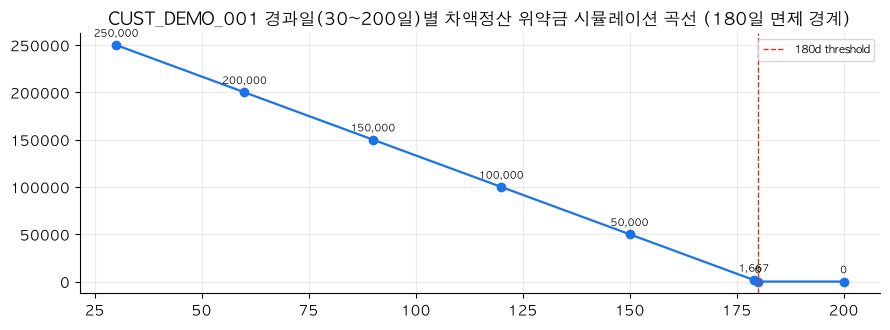

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       H.t("CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
           "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)"),
       vline=180, vline_label="180d threshold")


### 4. [Phase 7: 2-Pass 에이전트 End-to-End 답변 생성] Golden CQ(`GROUNDED`) 및 경계 조건(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`) 4단계 트레이스


#### CQ-01 (Subsidy & Net Price)
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"storage_gb": 256}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 643 | `job_r2pMUP_KlgPLGB4wX4oOKNzdP04R` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,334 tokens, LLM 23,651 ms / total 24.75 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> 질문하신 **AlphaPhone 16 Pro 256GB** 단말기 및 **5G Signature 115** 요금제에 대한 공시지원금 정책 데이터는 BigQuery 조회 결과에 존재하지 않아, 해당 조건의 공시지원금, 유통망 추가지원금 상한, 총 지원금 및 실구매가를 산출할 수 없습니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> 현재 온톨로지 DW(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)에 등록된 256GB 단말기 지원금 정책 데이터는 아래와 같습니다.
>
> #### 참고 (질문과 다른 조건의 단말기/요금제 데이터)
> - **iPhone 16 Pro 256GB**
>   - 요금제: `5G Premier Essential` (월 85,000원)
>   - 출고가(`factory_price_krw`): 1,700,000원
>   - 총 지원금(`total_subsidy_krw`): 460,000원 (정책 ID: `POL-2026-005`)
> - **Galaxy S26 Ultra 256GB**
>   - 요금제: `5G Premier Super` (월 130,000원) / 총 지원금: 575,000원 (정책 ID: `POL-2026-001`, 출고가: 1,698,400원)
>   - 요금제: `5G Premier Essential` (월 85,000원) / 총 지원금: 517,500원 (정책 ID: `POL-2026-002`, 출고가: 1,698,400원)
>   - 요금제: `5G Slim (Baseline Threshold)` (월 45,000원) / 총 지원금: 345,000원 (정책 ID: `POL-2026-003`, 출고가: 1,698,400원)
>   - 요금제: `5G Light (Below Baseline)` (월 37,000원) / 총 지원금: 172,500원 (정책 ID: `POL-2026-004`, 출고가: 1,6

#### CQ-02 (120d Prorated Penalty)
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 607 | `job_wJRfOxmE9aJ48Is67X4E8ClGQSGc` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,084 | `job_-FylYjmJSYq_YDdvD8I2WLJf9Zkb`, `job_GlpZfNsSPVqpRJ2rHJrpJ1W0LCa1` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 566 | `job_UPUB_E21KkbanOMCvFpX-mJupQnb` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,501 tokens, LLM 13,824 ms / total 16.09 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 **차액정산 위약금은 100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 정보**
>   * 고객 ID: `CUST_DEMO_001` (계약 ID: `CONTRACT_DEMO_101`)
>   * 계약 유형: 공시지원금 약정 (`PUBLIC_SUBSIDY`, 24개월)
>   * 복지 할인 여부: 해당 없음 (`NONE`)
>   * 유지 일수: 120일 (의무 유지 기간: 180일)
>   * 기기명: Galaxy S26 Ultra 256GB (`DEV-S26U-256`, 출고가: 1,698,400원)
>
> * **요금제 및 지원금 현황**
>   * 기존 요금제: 5G Premier Essential (`PLAN-5G-85`, 월 85,000원)
>     * 기존 기본 공시지원금: 450,000원 (추가지원금 67,500원 포함 총 지원금: 517,500원)
>   * 변경 대상 요금제: 5G Light (Below Baseline) (`PLAN-5G-37`, 월 37,000원)
>     * 변경 요금제 기본 공시지원금: 150,000원
>   * 기준선 요금: 월 45,000원 (변경 대상 요금제는 기준선 미만 요금제에 해당)
>
> * **위약금 산식 및 계산 내역**
>   * 산식: `(기존 기본 공시지원금 - 변경 요금제 기본 공시지원금) × (180 - 유지일수) / 180`
>   * 계산: `(450,000원 - 150,000원) × (180 - 120) / 180`
>     * `= 300,000원 × 60 / 180 = 100,000원`
>   * 위약금 상태: 일할 위약금 부과 (`PRORATED_PENALTY`, 최종 금액 100,000원)
>
> ---
>
> ### **규칙·원문 근거**
>
> * **적용 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   * **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   * **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   * **근거 청크**: 
>     * `DOC_CHUNK_003` (anchor: `anchor_47971ec8e4d8`)
>     * `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), anchor: `anchor_3003b683cea0`)
> * **참조 규칙**:
>   * `RULE_SUBSIDY_CAP` (`DOC_CHUNK_001`): 공시지원금 및 유통망 추가지원금(15%) 합산 규칙
>   * `RULE_TCO_24M` (`DOC_CHUNK_005`): 24개월 공시지원금 vs 25% 선택약정 총비용 비교 규칙
>
> ---
>
> ### **실행 정보**
> * **mcp_lookup_customer_profile**: `job_wJRfOxmE9aJ48Is67X4E8ClGQSGc`
> * **mcp_calculate_penalty_rule**: `job_GlpZfNsSPVqpRJ2rHJrpJ1W0LCa1` (연관 Job: `job_-FylYjmJSYq_YDdvD8I2WLJf9Zkb`)
> * **mcp_query_graph_and_wiki**: `job_UPUB_E21KkbanOMCvFpX-mJupQnb`

#### CQ-03 (Welfare Exemption)
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 512 | `job_oA5u87uDyPwODGKkcY3hE128EPic` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 577 | `job_PYfMH5n44ZmusQP-5zIx9m4a1DTo` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 962 | `job_-NEKaYtiiDz6v6tWLlyAxgIkIpbu`, `job_EHdmevD9t59v5X_M0_HT2y80e9-4` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,339 tokens, LLM 18,694 ms / total 20.75 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> **위약금이 면제되지 않습니다.**
>
> 고객(`CUST_DEMO_002`)의 시스템상 복지 자격 상태(`welfare_status`)는 **`NONE`**으로 등록되어 있어 위약금 면제 특례(`RULE_WELFARE_EXEMPT`) 대상에 해당하지 않습니다. 따라서 개통 후 95일 시점(의무유지기간 180일 미만)에 기준선(월 45,000원) 미만의 하위 요금제로 변경할 경우 차액정산 위약금이 부과됩니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> - **고객 ID**: `CUST_DEMO_002` (계약 ID: `CONTRACT_DEMO_102`)
> - **고객 세그먼트 / 연령대**: `General_Standard` / `30s-40s`
> - **복지 등록 상태 (`welfare_status`)**: `NONE`
> - **계약 유형**: `PUBLIC_SUBSIDY` (공시지원금 수혜 개통)
> - **현재 요금제**: `5G Premier Super` (월 130,000원)
> - **수령 지원금**: 기본 공시지원금 500,000원 + 추가지원금 75,000원 = 총 575,000원
> - **의무유지 기준**: 의무유지기간 180일, 기준선 요금 45,000원 (`baseline_fee_krw`)
> - **질문 기준 경과일수**: 95일 (180일 미만)
>
> ---
>
> ### **규칙 및 원문 근거**
> 1. **복지 위약금 면제 특례 규칙 (`RULE_WELFARE_EXEMPT`)**
>    - **적용 조건**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    - **내용**: 만 65세 이상 시니어 복지 특례(`SENIOR_EXEMPT`) 대상자 등에 한해 180일 이내라도 위약금이 면제(0원)되나, 해당 고객은 `NONE` 상태로 조건에 미부합합니다. (근거 청크: `DOC_CHUNK_004`, 앵커: `anchor_269d9c42e05c`)
> 2. **180일 기준선 의무유지 및 일할 차액위약금 규칙 (`RULE_SIX_PLAN_180D`)**
>    - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    - **내용**: 개통 후 180일 이내에 월 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180-95)/180)을 적용한 위약금이 부과됩니다. (근거 청크: `DOC_CHUNK_002`, `DOC_CHUNK_003`, 앵커: `anchor_3003b683cea0`, `anchor_47971ec8e4d8`)
>
> ---
>
> ### **실행 정보 (Job ID)**
> - 고객 프로필 조회: `job_oA5u87uDyPwODGKkcY3hE128EPic`
> - 온톨로지 그래프 탐색: `job_PYfMH5n44ZmusQP-5zIx9m4a1DTo`
> - 위약금 규칙 계산: `job_EHdmevD9t59v5X_M0_HT2y80e9-4` (`job_-NEKaYtiiDz6v6tWLlyAxgIkIpbu`)

#### BC-PARAM (Missing Customer/Device)
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 602 | `job_IyZtxJxkC7AF_3w-XBRpgTQcA9tM` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,636 tokens, LLM 23,647 ms / total 24.26 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 결론
>
> 180일 의무유지 기간 내에 기준선(월 45,000원) 미만 요금제인 **5G Light(월 37,000원)**로 하향 변경 시, **차액정산금(위약금)**이 발생합니다.
>
> 정확한 위약금 금액은 개통 당시 수령한 **최초 공시지원금(Initial Granted Subsidy)**과 단말기 기종에 따라 달라지며, 방금 개통(경과일수 0일 가정) 기준으로 계산 산식은 다음과 같습니다:
> - **위약금 산식**: `(최초 수혜 공시지원금 - 변경 요금제 공시지원금) × (180 - 경과일수) / 180`
> - 경과일수가 0일인 경우, **최초 공시지원금과 변경 요금제 지원금 간 차액의 100%**가 청구됩니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> BigQuery 온톨로지 그래프(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)에 등록된 단말기 및 요금제별 지원금 데이터는 다음과 같습니다:
>
> 1. **하향 대상 요금제 지원금**:
>    - 요금제: **5G Light (Below Baseline)** (월 37,000원)
>    - 공시지원금: 172,500원 (정책 ID: `POL-2026-004`, 단말: Galaxy S26 Ultra 256GB 기준)
>
> 2. **초기 요금제에 따른 차액정산 예시 (Galaxy S26 Ultra 256GB, 경과일수 0일 기준)**:
>    - **5G Premier Super** (월 130,000원 / 공시지원금 575,000원):
>      - 차액위약금: `(575,000원 - 172,500원) × (180 - 0) / 180 = 402,500원`
>    - **5G Premier Essential** (월 85,000원 / 공시지원금 517,500원):
>      - 차액위약금: `(517,500원 - 172,500원) × (180 - 0) / 180 = 345,000원`
>    - **5G Slim (Baseline Threshold)** (월 45,000원 / 공시지원금 345,000원):
>      - 차액위약금: `(345,000원 - 172,500원) × (180 - 0) / 180 = 172,500원`
>
> *(단, 시니어 만 65세 이상 또는 복지 요금제 전환 대상자인 경우 `RULE_WELFARE_EXEMPT`에 따라 0원 면제 적용)*
>
> ---
>
> ### 규칙·원문 근거
>
> - **규칙 ID**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - **DOC_CHUNK_002** (`anchor_3003b683cea0`): 공시지원금을 받은 가입자는 개통일로부터 180일 동안 기준선(5G 45,000원/월) 이상의 요금제를 유지해야 하며, 180일 이내 하향 시 경과일수를 반영한 차액정산금이 부과됨.
>   - **DOC_CHUNK_003** (`anchor_47971ec8e4d8`): 차액정산금 산식 `Penalty = (Initial Granted Subsidy - Lower Tier Subsidy) * (180 - Elapsed Days) / 180` 명시.
> - **규칙 ID**: `RULE_WELFARE_EXEMPT`
>   - **DOC_CHUNK_004** (`anchor_269d9c42e05c`): 시니어/복지 요금제 전환 특례 규정.
>
> ---
>
> ### 실행 정보
>
> - **BigQuery Job ID**: `job_IyZtxJxkC7AF_3w-XBRpgTQcA9tM`
> - **조회 엔진 및 그래프**: BigQuery (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)

#### BC-NOTFOUND (Unknown Entity)
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 497 | `job_g6RXuybZXIeybVzf2iH8xzOMvqzY` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 483 | `job_c0Ji7_9KzUdy62iEJV60QJ18HLGt` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 649 | `job_Qzeg5Xeu-_vMIyit5IY-HBVdpTbj` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 10,035 tokens, LLM 13,588 ms / total 15.22 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 결론
>
> 위약금 계산을 진행할 수 없습니다. 요청하신 고객(`CUST_NOT_EXIST_999`) 및 단말기(`QuantumFold 99`) 관련 정보가 입력 파라미터에 매핑되지 않았으며, 위약금 산정에 필요한 필수 파라미터가 누락되었습니다.
>
> **부족한 정보 (missing_slots):**
> - customer_id 또는 단말기(+가입 요금제)
> - 개통 후 경과일수
> - 변경 희망 요금제
>
> 단, 규정에 정의된 위약금 산정 규칙(`RULE_SIX_PLAN_180D`) 및 면제 규정은 아래와 같습니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> 요청 조건(`CUST_NOT_EXIST_999`, `QuantumFold 99`)과 직접 일치하는 데이터는 조회되지 않았으며, 데이터베이스에 등록된 단말기 및 요금제 기준 정보는 다음과 같습니다.
>
> **참고(질문과 다른 조건 - DW 내 보유 단말 및 요금제 정책):**
> - **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>   - `5G Premier Super` (월 130,000원): 기본지원금 500,000원, 추가지원금 75,000원, 총지원금 575,000원 (정책 ID: `POL-2026-001`)
>   - `5G Premier Essential` (월 85,000원): 기본지원금 450,000원, 추가지원금 67,500원, 총지원금 517,500원 (정책 ID: `POL-2026-002`)
>   - `5G Slim (Baseline Threshold)` (월 45,000원): 기본지원금 300,000원, 추가지원금 45,000원, 총지원금 345,000원 (정책 ID: `POL-2026-003`)
>   - `5G Light (Below Baseline)` (월 37,000원): 기본지원금 150,000원, 추가지원금 22,500원, 총지원금 172,500원 (정책 ID: `POL-2026-004`)
> - **Galaxy S26 Ultra 512GB** (출고가: 1,841,400원)
> - **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>   - `5G Premier Essential` (월 85,000원): 기본지원금 400,000원, 추가지원금 60,000원, 총지원금 460,000원 (정책 ID: `POL-2026-005`)
> - **iPhone 16 Pro 512GB** (출고가: 2,000,000원)
>
> ---
>
> ### 규칙·원문 근거
>
> - **RULE_SIX_PLAN_180D (180일 기준선 의무유지 및 일할 차액위약금 규칙)**:
>   - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **조건**: 개통 후 180일 미만(`elapsed_days < 180`) 유지 중 월정액 45,000원 미만(`target_plan_monthly_fee < 45000`) 요금제로 하향 변경 시 차액에 대한 일할 위약금 부과. 180일 이상 경과 시 위약금 0원.
>   - **근거 청크**: `DOC_CHUNK_002`, `DOC_CHUNK_003` (anchor: `anchor_47971ec8e4d8`, `anchor_3003b683cea0`)
> - **RULE_WELFARE_EXEMPT (시니어·복지 요금제 전환 위약금 면제 특례)**:
>   - **조건**: 만 65세 이상 시니어 또는 복지 특례 대상자가 해당 요금제로 변경 시 180일 이내라도 위약금 0원 면제.
>   - **근거 청크**: `DOC_CHUNK_004` (anchor: `anchor_269d9c42e05c`)
>
> ---
>
> ### 실행 정보
>
> - **고객 프로필 조회 Job ID**: `job_g6RXuybZXIeybVzf2iH8xzOMvqzY`
> - **위약금 규칙 조회 Job ID**: `job_c0Ji7_9KzUdy62iEJV60QJ18HLGt`
> - **그래프 및 온톨로지 조회 Job ID**: `job_Qzeg5Xeu-_vMIyit5IY-HBVdpTbj`

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,query_graph_and_wiki,2,6334,23651,643,24.75
1,CQ-02,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6501,13824,2256,16.09
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6339,18694,2051,20.75
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,6636,23647,602,24.26
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,10035,13588,1629,15.22


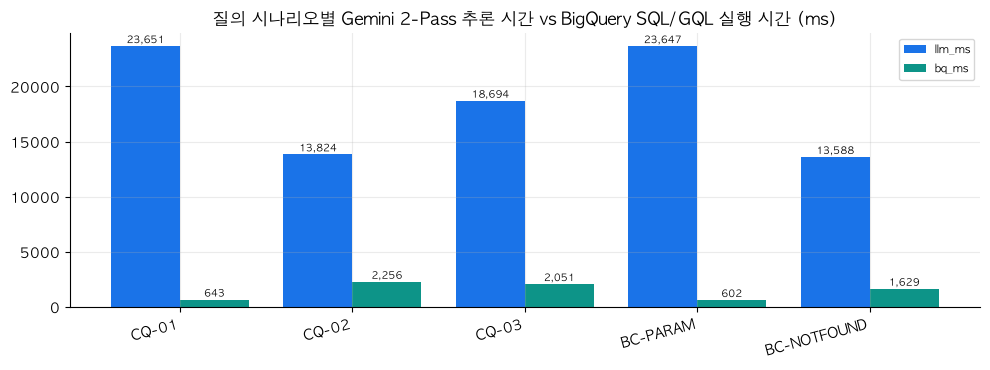

In [5]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              H.t("질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)",
                  "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)"))


### Q&A
- **Q.** AI FDE 에이전트는 위약금 계산 오류나 미등록 단말기/고객 환각을 어떻게 방지하나요?
  - **A.** `resolve_params()`가 BigQuery 실시간 카탈로그(`get_live_catalog()`)와 대조하여 미등록 단말·요금제·고객 ID를 즉시 필터링하고, 모든 금액 계산은 LLM이 아닌 `mcp_calculate_penalty_rule` 내부 BigQuery SQL 산식으로만 수행하며, 필수 정보 누락 시 `INSUFFICIENT_PARAMETERS`, 조건 불일치 시 `MATCH_NOT_FOUND` 상태를 반환합니다.

### Data Analysis Key Findings
- `CUST_DEMO_001` 경과일 시뮬레이션(30~200일) 결과, 위약금은 30일차 `250,000원`에서 120일차 `100,000원`, 179일차 `1,667원`으로 선형 감소하며 180일 도래 즉시 `0원`(`EXEMPT_RETENTION_COMPLETED`)으로 전환됩니다.
- Golden CQ(`CQ-01`~`CQ-03`)는 모두 `GROUNDED` 상태와 함께 정확한 금액(`575,000원`, `100,000원`, `0원`) 및 SHA-256 청크 앵커·BigQuery Job ID를 인용하여 답변했습니다.
- 필수 슬롯 누락 질의(`BC-PARAM`)는 `INSUFFICIENT_PARAMETERS`로, 미등록 고객/단말 질의(`BC-NOTFOUND`)는 `MATCH_NOT_FOUND`로 정확히 분기하여 수치 환각을 차단했습니다.

### Insights or Next Steps
- 마지막 단계인 `Stage 5 (리니지·검증)` 노트북으로 이동하여 원천 파일부터 CQ 답변까지의 4-Tier 데이터 리니지 그래프와 Golden CQ 5종 / Boundary 50회 반복 벤치마크 배포 게이트를 검증하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough.ipynb) ｜ [➡️ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb) ｜ [🌐 English Version](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [📖 방법론 문서](../methodology/04_stage4_agent_and_mcp_ko.md)
